In [2]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("online_retail.db")


In [21]:
def customer_feature_engineering(observation_date):
    observation_date = pd.to_datetime(observation_date)

    # Exclusive upper bound: includes the entire observation date
    next_day = (
        observation_date + pd.Timedelta(days=1)
    ).strftime("%Y-%m-%d")

    # 1. RFM features
    rfm_query = """
        SELECT
            c.customer_id,
            MAX(t.invoicedate) AS last_purchase,
            COUNT(DISTINCT t.invoice) AS frequency,
            SUM(t.revenue) AS monetary
        FROM customers AS c
        JOIN transactions AS t
            ON c.customer_id = t.customer_id
        WHERE t.invoicedate < ?
          AND NOT t.is_return
          AND NOT t.is_non_product
          AND NOT t.is_guest
        GROUP BY c.customer_id
    """

    rfm = pd.read_sql_query(
        rfm_query,
        conn,
        params=[next_day]
    )

    rfm["last_purchase"] = pd.to_datetime(rfm["last_purchase"])

    rfm["recency"] = (
        observation_date - rfm["last_purchase"]
    ).dt.days

    rfm_features = rfm[
        ["customer_id", "recency", "frequency", "monetary"]
    ].copy()

    # 2. Cohort and days since first purchase
    purchases_query = """
        SELECT DISTINCT
            customer_id,
            invoice,
            invoicedate
        FROM transactions
        WHERE invoicedate < ?
          AND customer_id != 0
          AND NOT is_return
          AND NOT is_non_product
        ORDER BY customer_id, invoicedate
    """

    purchases = pd.read_sql_query(
        purchases_query,
        conn,
        params=[next_day]
    )

    purchases["invoicedate"] = pd.to_datetime(
        purchases["invoicedate"]
    )

    first_purchase = (
        purchases.groupby("customer_id")["invoicedate"]
        .min()
        .reset_index()
    )

    first_purchase["cohort_month"] = (
        first_purchase["invoicedate"].dt.to_period("M")
    )

    first_purchase["days_since_first_purchase"] = (
        observation_date - first_purchase["invoicedate"]
    ).dt.days

    customer_features = rfm_features.merge(
        first_purchase[
            [
                "customer_id",
                "cohort_month",
                "days_since_first_purchase"
            ]
        ],
        on="customer_id",
        how="left"
    )

    # 3. Average order value
    aov_query = """
        SELECT
            customer_id,
            COUNT(DISTINCT invoice) AS number_of_orders,
            SUM(revenue) AS total_revenue
        FROM transactions
        WHERE invoicedate < ?
          AND customer_id != 0
          AND NOT is_return
          AND NOT is_non_product
        GROUP BY customer_id
    """

    aov = pd.read_sql_query(
        aov_query,
        conn,
        params=[next_day]
    )

    aov["average_order_value"] = (
        aov["total_revenue"] / aov["number_of_orders"]
    )

    customer_features = customer_features.merge(
        aov[["customer_id", "average_order_value"]],
        on="customer_id",
        how="left"
    )

    # 4. Product diversity
    product_diversity_query = """
        SELECT
            customer_id,
            COUNT(DISTINCT stockcode) AS distinct_products_bought
        FROM transactions
        WHERE invoicedate < ?
          AND customer_id != 0
          AND NOT is_return
          AND NOT is_non_product
        GROUP BY customer_id
    """

    product_diversity = pd.read_sql_query(
        product_diversity_query,
        conn,
        params=[next_day]
    )

    customer_features = customer_features.merge(
        product_diversity,
        on="customer_id",
        how="left"
    )

    return customer_features

In [ ]:
observation_date1 = pd.Timestamp("2010-03-31")
observation_date2 = pd.Timestamp("2010-08-31")

customer_features1 = customer_feature_engineering(
    observation_date1
)

customer_features2 = customer_feature_engineering(
    observation_date2
)

print(customer_features1.shape)
print(customer_features2.shape)

print(customer_features1.columns.tolist())
print(customer_features2.columns.tolist())

(2135, 8)
(3299, 8)
['customer_id', 'recency', 'frequency', 'monetary', 'cohort_month', 'days_since_first_purchase', 'average_order_value', 'distinct_products_bought']
['customer_id', 'recency', 'frequency', 'monetary', 'cohort_month', 'days_since_first_purchase', 'average_order_value', 'distinct_products_bought']


1- kanchofo kola client akhir purchase dyalo  
2- observation_date1 moraha b 136 days wach andna chi transaction if oui 
 add customer_features1 is_churned 0
 else kanhoto fiha 1 
3- hakda kan3amro lsnapcchoot lwl 
4- kan3tiw lel model yt3alm mn had table 

In [23]:
def add_churn_target(customer_features, observation_date, churn_cutoff=136):
    observation_date = pd.to_datetime(observation_date)

    start_date = (
        observation_date + pd.Timedelta(days=1)
    ).strftime("%Y-%m-%d")

    end_date = (
        observation_date + pd.Timedelta(days=churn_cutoff + 1)
    ).strftime("%Y-%m-%d")
 # this query selects distinct customer IDs from the transactions table where the invoice date is within the specified range, 
 # the customer ID is not zero, and the transaction is not a return or a non-product. This helps identify customers who made purchases 
 # in the future period after the observation date.
    future_purchases_query = """
        SELECT DISTINCT customer_id
        FROM transactions
        WHERE invoicedate >= ?
          AND invoicedate < ?
          AND customer_id != 0
          AND NOT is_return
          AND NOT is_non_product
    """

    future_purchases = pd.read_sql_query(
        future_purchases_query,
        conn,
        params=[start_date, end_date]
    )

    future_customer_ids = set(future_purchases["customer_id"])

    result = customer_features.copy()

    result["churned"] = (
        ~result["customer_id"].isin(future_customer_ids)
    ).astype(int)

    return result

In [24]:
snapshot1 = add_churn_target(
    customer_features1,
    observation_date1,
    churn_cutoff=136
)

print(snapshot1.shape)
print(snapshot1["churned"].value_counts())

(2135, 9)
churned
0    1370
1     765
Name: count, dtype: int64


In [28]:
snapshot2 = add_churn_target(
    customer_features2,
    observation_date2,
    churn_cutoff=136
)

print(snapshot2.shape)
print(snapshot2["churned"].value_counts())

(3299, 9)
churned
0    2057
1    1242
Name: count, dtype: int64


In [29]:
import pandas as pd

# Prepare copies
train_df = snapshot1.copy()
test_df = snapshot2.copy()

# Convert cohort_month to a numeric representation
for df in [train_df, test_df]:
    df["cohort_month"] = (
        df["cohort_month"].astype(str)
    )

    df["cohort_month"] = (
        pd.PeriodIndex(df["cohort_month"], freq="M")
        .astype("int64")
    )

# Separate features (X) and target (y)
X_train = train_df.drop(
    columns=["customer_id", "churned"]
)
y_train = train_df["churned"]

X_test = test_df.drop(
    columns=["customer_id", "churned"]
)
y_test = test_df["churned"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2135, 7)
y_train: (2135,)
X_test: (3299, 7)
y_test: (3299,)


In [30]:
print("Missing values in X_train:")
print(X_train.isnull().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum())

print("\nData types:")
print(X_train.dtypes)

Missing values in X_train:
recency                      0
frequency                    0
monetary                     0
cohort_month                 0
days_since_first_purchase    0
average_order_value          0
distinct_products_bought     0
dtype: int64

Missing values in X_test:
recency                      0
frequency                    0
monetary                     0
cohort_month                 0
days_since_first_purchase    0
average_order_value          0
distinct_products_bought     0
dtype: int64

Data types:
recency                        int64
frequency                      int64
monetary                     float64
cohort_month                   int64
days_since_first_purchase      int64
average_order_value          float64
distinct_products_bought       int64
dtype: object


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

/Users/rihabtouil/Desktop/BI/.venv_mac/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/rihabtouil/Desktop/BI/.venv_mac/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/rihabtouil/Desktop/BI/.venv_mac/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept


Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [33]:
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    confusion_matrix
)

y_pred = logistic_model.predict(X_test)
y_proba = logistic_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("PR-AUC:", average_precision_score(y_test, y_proba))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.62      0.70      2057
           1       0.54      0.74      0.62      1242

    accuracy                           0.66      3299
   macro avg       0.67      0.68      0.66      3299
weighted avg       0.70      0.66      0.67      3299

PR-AUC: 0.5890589930448531
Confusion Matrix:
[[1273  784]
 [ 322  920]]


/Users/rihabtouil/Desktop/BI/.venv_mac/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/rihabtouil/Desktop/BI/.venv_mac/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/rihabtouil/Desktop/BI/.venv_mac/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/rihabtouil/Desktop/BI/.venv_mac/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/rihabtouil/Desktop/BI/.venv_mac/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/rihabtouil/Desktop/BI/.venv_mac/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [36]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

In [37]:
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    confusion_matrix
)

print(classification_report(y_test, xgb_pred))
print("PR-AUC:", average_precision_score(y_test, xgb_proba))
print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.71      0.75      0.73      2057
           1       0.55      0.50      0.52      1242

    accuracy                           0.65      3299
   macro avg       0.63      0.62      0.63      3299
weighted avg       0.65      0.65      0.65      3299

PR-AUC: 0.5487668102028183
Confusion Matrix:
[[1543  514]
 [ 625  617]]


In [38]:
import optuna
import numpy as np

from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score

/Users/rihabtouil/Desktop/BI/.venv_mac/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [39]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "eval_metric": "logloss",
        "random_state": 42,
        "n_jobs": -1
    }

    model = XGBClassifier(**params)

    cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=1
    )

    return scores.mean()



In [40]:
study = optuna.create_study(direction="maximize")

study.optimize(objective, n_trials=30)

print("Best PR-AUC:", study.best_value)
print("Best parameters:", study.best_params)

[I 2026-10-23 21:20:11,309] A new study created in memory with name: no-name-4ad97ba0-96e4-420d-a192-27eff1828aaa
[I 2026-10-23 21:20:12,856] Trial 0 finished with value: 0.48247760132534956 and parameters: {'n_estimators': 427, 'max_depth': 6, 'learning_rate': 0.09923769974258628, 'subsample': 0.8736630880936339, 'colsample_bytree': 0.9490425633367472, 'min_child_weight': 3}. Best is trial 0 with value: 0.48247760132534956.
[I 2026-10-23 21:20:13,170] Trial 1 finished with value: 0.5051650360442136 and parameters: {'n_estimators': 108, 'max_depth': 4, 'learning_rate': 0.16656122842746515, 'subsample': 0.90366366006425, 'colsample_bytree': 0.7964390695456383, 'min_child_weight': 3}. Best is trial 1 with value: 0.5051650360442136.
[I 2026-10-23 21:20:14,355] Trial 2 finished with value: 0.5249779391061781 and parameters: {'n_estimators': 396, 'max_depth': 5, 'learning_rate': 0.013195543652460456, 'subsample': 0.7802531569086201, 'colsample_bytree': 0.8118033734648817, 'min_child_weight'

Best PR-AUC: 0.5482125831069733
Best parameters: {'n_estimators': 350, 'max_depth': 2, 'learning_rate': 0.014284544538733793, 'subsample': 0.9527827129098942, 'colsample_bytree': 0.8260227823761631, 'min_child_weight': 1}


In [41]:
best_model = XGBClassifier(
    **study.best_params,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

In [42]:
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    confusion_matrix
)

print(classification_report(y_test, y_pred))
print("PR-AUC:", average_precision_score(y_test, y_proba))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.72      0.81      0.76      2057
           1       0.60      0.47      0.53      1242

    accuracy                           0.68      3299
   macro avg       0.66      0.64      0.64      3299
weighted avg       0.67      0.68      0.67      3299

PR-AUC: 0.5825463214593896
Confusion Matrix:
[[1666  391]
 [ 657  585]]


In [43]:
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(y_test, y_proba)

print(f"Brier Score: {brier:.4f}")

Brier Score: 0.1985


Matplotlib is building the font cache; this may take a moment.


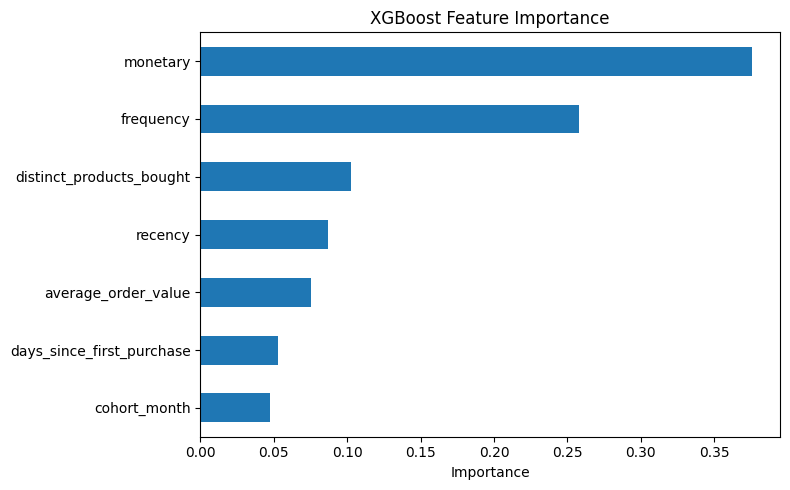

In [45]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    best_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

feature_importance.plot(kind="barh", figsize=(8, 5))
plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [46]:
import shap
import matplotlib.pyplot as plt

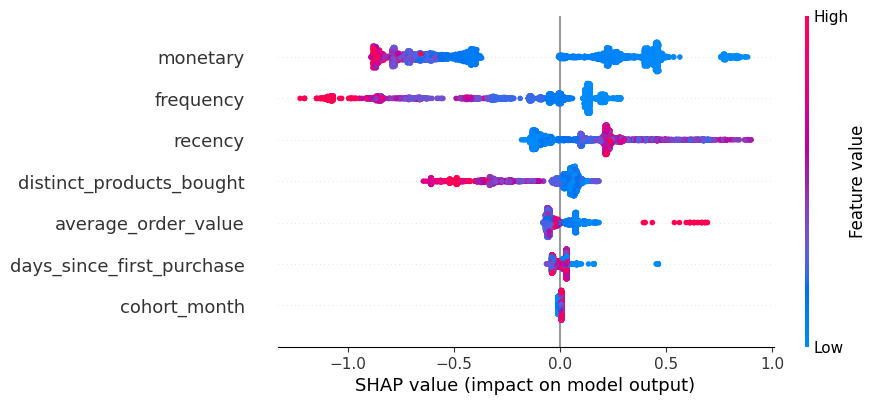

In [47]:
explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X_test)

shap.plots.beeswarm(shap_values)

In [48]:
import joblib
from pathlib import Path

model_path = Path("../models/churn_model.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(best_model, model_path)

print("Model saved successfully!")

Model saved successfully!
